# ESOL 溶解度：随机森林 + MLP + GNN

**任务**：根据 SMILES 预测水溶解度 `logS`。

**同一数据、同一划分**，对比三种表示/模型：

| 模型 | 分子表示 | 作用 |
|------|----------|------|
| **RandomForest** | Morgan 指纹（2048） | 强基线（只出现一次） |
| **MLP** | 6 维 RDKit 描述符 | 衔接全连接网络 |
| **Tiny GNN** | 原子图 + 消息传递 | 显式使用化学键连接 |

**数据**：Delaney / ESOL（MoleculeNet），约 1128 分子。


In [1]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# RDKit：读分子、描述符、指纹、位向量转 NumPy
from rdkit import Chem, DataStructs, RDLogger
from rdkit.Chem import Descriptors, rdFingerprintGenerator

# sklearn：划分数据、随机森林、回归指标
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

# PyTorch：定义 MLP / GNN、小批量训练
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset, Dataset

RDLogger.DisableLog("rdApp.*")  # 关掉无效 SMILES 时 RDKit 的刷屏警告
plt.rcParams["axes.unicode_minus"] = False  # 负号用 ASCII，避免坐标轴方框
torch.manual_seed(42)
np.random.seed(42)

# --- 定位数据文件：cwd 不一定等于 notebook 所在目录，故尝试多种路径 ---
_NB_DIR = Path.cwd()  # 当前工作目录
if (_NB_DIR / "data" / "delaney-processed.csv").exists():
    # 情况1：在 aidd/ 下启动
    DATA_PATH = _NB_DIR / "data" / "delaney-processed.csv"
elif (_NB_DIR / ".." / "data" / "delaney-processed.csv").exists():
    # 情况2：在 aidd/notebooks/ 下启动 → 上一级的 data/
    DATA_PATH = (_NB_DIR / ".." / "data" / "delaney-processed.csv").resolve()
else:
    # 情况3：兜底绝对路径（本机仓库位置）
    DATA_PATH = Path(r"d:\MachineLearning\aidd\data\delaney-processed.csv")

RANDOM_STATE = 42  # 固定随机种子，划分/模型可复现
EPOCHS_MLP = 120
EPOCHS_GNN = 110
HIDDEN = 64
LR = 1e-3
# Morgan 指纹生成器：radius=2≈ECFP4 思路，fpSize=2048 维 0/1 向量
morgan_gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)

# print("cwd:", os.getcwd())
# print("data:", DATA_PATH, DATA_PATH.exists())
# print("torch:", torch.__version__, "cuda:", torch.cuda.is_available())


## 1. 读数据

标签列：`measured log solubility in mols per litre`（实测 logS）。


In [2]:
# 读入 Delaney/ESOL 公开表（SMILES + 实测溶解度等）
df = pd.read_csv(DATA_PATH)
# 列名过长 → 改成短名 logS，方便后面写代码
df = df.rename(columns={
    "measured log solubility in mols per litre": "logS",  # 标签：实测 log 溶解度
})
# 本项目只用这三列；.copy() 避免后续改表时出现 SettingWithCopy 警告
df = df[["Compound ID", "smiles", "logS"]].copy()
print(df.shape)  # (样本数, 3)
df.head(3)  # 预览前几行，确认读对了


(1128, 3)


,Compound ID,smiles,logS
0,Amigdalin,OCC3OC(OCC2OC(OC(C#N)c1ccccc1)C(O)C(O)C2O)C(O)...,-0.77
1,Fenfuram,Cc1occc1C(=O)Nc2ccccc2,-3.30
2,citral,CC(C)=CCCC(C)=CC(=O),-2.06


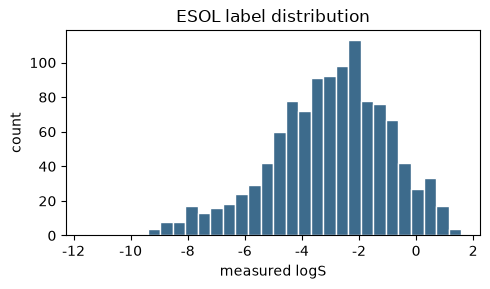

In [3]:
# 看标签分布：溶解度大致范围、是否严重偏斜（影响怎么理解误差）
plt.figure(figsize=(5, 3))
plt.hist(df["logS"], bins=30, color="#3d6b8c", edgecolor="white")
plt.xlabel("measured logS")
plt.ylabel("count")
plt.title("ESOL label distribution")
plt.tight_layout()
plt.show()


## 2. 三种特征：描述符、指纹、分子图

- **描述符**（6 维）：分子量、LogP、氢键供/受体、可旋转键、TPSA → MLP
- **Morgan 指纹**（2048 维）：radius=2 → RF
- **原子图**：节点特征 + 行归一化邻接 → GNN

只遍历数据一次，同时生成三种表示；解析失败的 SMILES 跳过。


In [4]:
# 六个与溶解/药化相关的描述符函数（维数少，适合 MLP）
DESC_FUNCS = [
    Descriptors.MolWt,              # 分子量
    Descriptors.MolLogP,            # 脂水分配相关（疏水）
    Descriptors.NumHDonors,         # 氢键供体数
    Descriptors.NumHAcceptors,      # 氢键受体数
    Descriptors.NumRotatableBonds,  # 可旋转键（柔性）
    Descriptors.TPSA,               # 拓扑极性表面积
]

ELEMENTS = ["C", "N", "O", "F", "P", "S", "Cl", "Br", "I"]
ELEM2IDX = {e: i for i, e in enumerate(ELEMENTS)}
# one-hot(元素+其它) + degree + aromatic + formal_charge → 共 9+1+1+1+1 = 13
F_DIM = len(ELEMENTS) + 1 + 3


def featurize_desc_fp(smiles: str, n_bits: int = 2048):
    """一个 SMILES → (描述符向量, 指纹向量)；失败返回 (None, None)。"""
    mol = Chem.MolFromSmiles(smiles)  # 字符串 → 分子对象
    if mol is None:                   # 无效 SMILES：跳过该样本
        return None, None
    # 逐个算描述符，拼成长度 6 的 float32 向量
    desc = np.array([f(mol) for f in DESC_FUNCS], dtype=np.float32)
    fp = morgan_gen.GetFingerprint(mol)  # RDKit 位向量对象
    fp_arr = np.zeros((n_bits,), dtype=np.float32)  # 先占位全 0
    DataStructs.ConvertToNumpyArray(fp, fp_arr)     # 写入 0/1，供 sklearn 使用
    return desc, fp_arr


def mol_to_graph(smiles: str):
    """返回 (X[n,F], A_norm[n,n])；解析失败返回 None。"""
    m = Chem.MolFromSmiles(smiles)
    if m is None:
        return None
    n = m.GetNumAtoms()
    if n == 0:
        return None

    X = np.zeros((n, F_DIM), dtype=np.float32)
    for atom in m.GetAtoms():
        i = atom.GetIdx()
        sym = atom.GetSymbol()
        if sym in ELEM2IDX:
            X[i, ELEM2IDX[sym]] = 1.0
        else:
            X[i, len(ELEMENTS)] = 1.0  # 其它元素
        X[i, len(ELEMENTS) + 1] = atom.GetDegree()
        X[i, len(ELEMENTS) + 2] = 1.0 if atom.GetIsAromatic() else 0.0
        # 形式电荷压到 [-2, 2] 再放进特征
        X[i, len(ELEMENTS) + 3] = float(np.clip(atom.GetFormalCharge(), -2, 2))

    A = np.eye(n, dtype=np.float32)  # 自环
    for bond in m.GetBonds():
        i, j = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()
        A[i, j] = A[j, i] = 1.0   # 双向图

    # 行归一化：每个原子对「自己+邻居」做平均聚合
    deg = A.sum(axis=1, keepdims=True)
    A_norm = A / np.maximum(deg, 1.0)  # deg里每个数和1.0比，谁大留谁；避免原子度数为0时出现除0
    return X, A_norm


# 收集所有成功分子的特征与标签
descs, fps, graphs, labels, keep_smiles = [], [], [], [], []
n_bad = 0
for smi, yv in zip(df["smiles"], df["logS"]):
    d, f = featurize_desc_fp(smi)
    g = mol_to_graph(smi)
    if d is None or g is None:
        n_bad += 1
        continue  # 丢掉解析失败的行，保证 X/y 对齐
    descs.append(d)
    fps.append(f)
    graphs.append(g)
    labels.append(float(yv))
    keep_smiles.append(smi)

X_desc = np.vstack(descs)               # (N, 6)    描述符矩阵 → 给 MLP
X_fp = np.vstack(fps)                   # (N, 2048) 指纹矩阵 → 给随机森林
y = np.asarray(labels, dtype=np.float32)  # (N,) 溶解度标签
print(f"可用分子: {len(y)}, 无效 SMILES: {n_bad}")
print("描述符 shape:", X_desc.shape, "指纹 shape:", X_fp.shape, "图数量:", len(graphs))
print(
    "原子数分布: min/median/max =",
    int(np.min([g[0].shape[0] for g in graphs])),
    int(np.median([g[0].shape[0] for g in graphs])),
    int(np.max([g[0].shape[0] for g in graphs])),
)


可用分子: 1128, 无效 SMILES: 0
描述符 shape: (1128, 6) 指纹 shape: (1128, 2048) 图数量: 1128
原子数分布: min/median/max = 1 12 55


## 3. 统一划分训练 / 测试

用下标划分，保证 RF / MLP / GNN 用 **同一批** 训练集与测试集分子。


In [5]:
# 用「下标」划分：保证指纹、描述符、图、标签用同一批 train/test 分子
idx = np.arange(len(y))  # [0, 1, ..., N-1]
idx_train, idx_test = train_test_split(
    idx, test_size=0.2, random_state=RANDOM_STATE
)  # 80% 训练 / 20% 测试；固定种子可复现

# 多套数组用同一套下标切片（对齐）
X_fp_train, X_fp_test = X_fp[idx_train], X_fp[idx_test]
X_desc_train, X_desc_test = X_desc[idx_train], X_desc[idx_test]
y_train, y_test = y[idx_train], y[idx_test]

# 描述符标准化：只在训练集上估 μ、σ，再应用到测试集（防泄露）
desc_mean = X_desc_train.mean(axis=0)           # 每列均值，shape (6,)
desc_std = X_desc_train.std(axis=0) + 1e-8      # 每列标准差；+1e-8 防除零
X_desc_train_s = (X_desc_train - desc_mean) / desc_std  # 训练特征 ~ 均值0方差1
X_desc_test_s = (X_desc_test - desc_mean) / desc_std    # 测试用同一套 μ、σ

# 指纹一般不标准化：已是 0/1，树模型也不强依赖尺度
print(f"train: {len(y_train)}, test: {len(y_test)}")


train: 902, test: 226


## 4. 基线：Morgan 指纹 + 随机森林

用来对照「拍扁指纹」vs「描述符 MLP」vs「显式图」。


In [6]:
# 基线：Morgan 指纹 + 随机森林回归（结构信息细，通常很强）
rf = RandomForestRegressor(
    n_estimators=200,          # 200 棵树，越稳越慢
    max_depth=None,            # 不限制深度，树可充分分裂
    n_jobs=-1,                 # 用满 CPU 并行
    random_state=RANDOM_STATE, # 可复现
)
rf.fit(X_fp_train, y_train)      # 只用训练集拟合
pred_rf = rf.predict(X_fp_test)  # 在测试集上预测 logS

# RMSE：与 logS 同量纲，越小越好；R²：越接近 1 越好
rmse_rf = float(np.sqrt(mean_squared_error(y_test, pred_rf)))
r2_rf = float(r2_score(y_test, pred_rf))
print(f"RandomForest  |  RMSE={rmse_rf:.4f}  R2={r2_rf:.4f}")


RandomForest  |  RMSE=1.1668  R2=0.7120


## 5. PyTorch MLP：描述符 → logS

特征用 6 维描述符（训练快、好懂）。


In [7]:
class SolubilityMLP(nn.Module):
    """描述符 → logS 的小型全连接网络（MLP）。"""

    def __init__(self, in_dim: int):
        super().__init__()  # 必须调用，注册子模块
        self.net = nn.Sequential(
            nn.Linear(in_dim, 64),  # 6 → 64
            nn.ReLU(),              # 非线性，否则多层等价一层线性
            nn.Dropout(0.1),        # 训练时随机丢 10% 神经元，减轻过拟合
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1),       # 回归：输出 1 个数（logS）
        )

    def forward(self, x):
        # squeeze(-1)：把 (batch, 1) 压成 (batch,)，与 y 形状一致好算 MSE
        return self.net(x).squeeze(-1)


device = torch.device("cpu")  # 本机学习用 CPU 足够
model_mlp = SolubilityMLP(X_desc_train_s.shape[1]).to(device)  # in_dim=6
opt_mlp = torch.optim.Adam(model_mlp.parameters(), lr=1e-3)  # 自适应学习率优化器
loss_fn = nn.MSELoss()  # 回归常用均方误差

# 训练集：特征与标签绑成 Dataset，再按 batch 取出
train_ds_mlp = TensorDataset(
    torch.from_numpy(X_desc_train_s),  # NumPy → Tensor
    torch.from_numpy(y_train),
)
train_loader_mlp = DataLoader(train_ds_mlp, batch_size=64, shuffle=True)  # 每步 64 条并打乱

# 测试集较小：整份转 Tensor，每个 epoch 末尾一次前向即可
X_test_t = torch.from_numpy(X_desc_test_s).to(device)
y_test_t = torch.from_numpy(y_test).to(device)

history_mlp = []  # 记录 (train_mse, test_mse) 供画曲线
for epoch in range(1, EPOCHS_MLP + 1):
    # ----- 训练阶段 -----
    model_mlp.train()  # 启用 Dropout 等训练行为
    total = 0.0
    for xb, yb in train_loader_mlp:
        xb, yb = xb.to(device), yb.to(device)
        pred = model_mlp(xb)           # 1. 前向
        loss = loss_fn(pred, yb)       # 2. 损失
        opt_mlp.zero_grad()            # 3. 清空旧梯度
        loss.backward()                # 4. 反向传播
        opt_mlp.step()                 # 5. 更新参数
        total += loss.item() * len(xb)  # 按样本数加权，后面再平均
    train_mse = total / len(train_ds_mlp)

    # ----- 测试阶段（不更新参数）-----
    model_mlp.eval()  # 关闭 Dropout
    with torch.no_grad():  # 不建计算图，省内存加快速度
        test_pred = model_mlp(X_test_t)
        test_mse = loss_fn(test_pred, y_test_t).item()
    history_mlp.append((train_mse, test_mse))
    if epoch % 20 == 0 or epoch == 1:
        print(f"[MLP] Epoch {epoch:3d}  train_MSE={train_mse:.4f}  test_MSE={test_mse:.4f}")

# 用最后一轮的测试预测算与 RF 同口径的 RMSE / R²
pred_mlp = test_pred.cpu().numpy()  # Tensor → NumPy，供 sklearn 指标函数
rmse_mlp = float(np.sqrt(mean_squared_error(y_test, pred_mlp)))
r2_mlp = float(r2_score(y_test, pred_mlp))
print(f"\nMLP(descriptors)  |  RMSE={rmse_mlp:.4f}  R2={r2_mlp:.4f}")


[MLP] Epoch   1  train_MSE=12.3875  test_MSE=11.7274
[MLP] Epoch  20  train_MSE=0.7633  test_MSE=0.9809
[MLP] Epoch  40  train_MSE=0.6178  test_MSE=0.8622
[MLP] Epoch  60  train_MSE=0.5571  test_MSE=0.8176
[MLP] Epoch  80  train_MSE=0.5288  test_MSE=0.8070
[MLP] Epoch 100  train_MSE=0.5006  test_MSE=0.7869
[MLP] Epoch 120  train_MSE=0.4742  test_MSE=0.7780

MLP(descriptors)  |  RMSE=0.8821  R2=0.8354


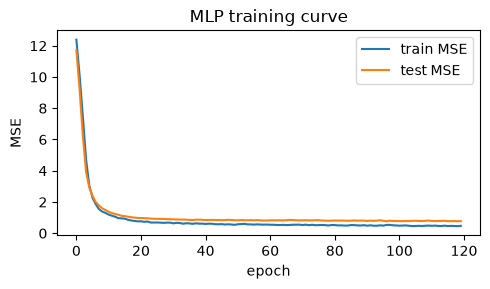

In [8]:
# 把 history 画成曲线：看是否过拟合（train 降、test 升）
hist = np.array(history_mlp)  # shape (EPOCHS, 2)
plt.figure(figsize=(5, 3))
plt.plot(hist[:, 0], label="train MSE")
plt.plot(hist[:, 1], label="test MSE")
plt.xlabel("epoch")
plt.ylabel("MSE")
plt.legend()
plt.title("MLP training curve")
plt.tight_layout()
plt.show()


## 6. 两层消息传递 GNN

每一层：`H' = ReLU( A_norm @ Linear(H) )`  
分子向量：节点维 **mean readout** → MLP 头 → 标量 logS。

`batch_size=1`：不同分子原子数不同，入门阶段最简单；全量 CPU 可接受。


In [9]:
class MolGraphDataset(Dataset):
    def __init__(self, graphs, labels):
        self.graphs = graphs
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        X, A = self.graphs[i]
        return (
            torch.from_numpy(X),     # 把 NumPy 数组直接变成 Tensor（共享同一块内存，通常更快）
            torch.from_numpy(A),
            torch.tensor(self.labels[i], dtype=torch.float32),  # labels[i] 是 Python 标量
        )


class TinyMPGNN(nn.Module):
    """两层 MP + mean readout + 回归头（纯 PyTorch，无 PyG）。"""

    def __init__(self, in_dim, hidden=64):
        super().__init__()
        self.lin1 = nn.Linear(in_dim, hidden)
        self.lin2 = nn.Linear(hidden, hidden)
        self.head = nn.Sequential(
            nn.Linear(hidden, 32),
            nn.ReLU(),
            nn.Linear(32, 1),
        )

    def forward(self, X, A):
        # X: [n, F], A: [n, n] 已行归一化
        H = F.relu(A @ self.lin1(X))
        H = F.relu(A @ self.lin2(H))
        g = H.mean(dim=0)           # readout：分子级向量；聚合所有节点信息预测全局特征
        return self.head(g).squeeze(-1)


# 前面 MLP 已大量消耗 torch 随机数；这里重新播种，使 GNN 初始化/打乱与单独跑 06 更接近
torch.manual_seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

train_set_gnn = MolGraphDataset(
    [graphs[i] for i in idx_train],
    [float(y[i]) for i in idx_train],
)
test_set_gnn = MolGraphDataset(
    [graphs[i] for i in idx_test],
    [float(y[i]) for i in idx_test],
)
_gnn_gen = torch.Generator().manual_seed(RANDOM_STATE)
train_loader_gnn = DataLoader(
    train_set_gnn, batch_size=1, shuffle=True, generator=_gnn_gen
)  # batch_size=1：不同分子原子数不同，入门阶段最简单
test_loader_gnn = DataLoader(test_set_gnn, batch_size=1)

model_gnn = TinyMPGNN(F_DIM, hidden=HIDDEN).to(device)
opt_gnn = torch.optim.Adam(model_gnn.parameters(), lr=LR)
print(model_gnn)
print("参数量:", sum(p.numel() for p in model_gnn.parameters()))


TinyMPGNN(
  (lin1): Linear(in_features=13, out_features=64, bias=True)
  (lin2): Linear(in_features=64, out_features=64, bias=True)
  (head): Sequential(
    (0): Linear(in_features=64, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=1, bias=True)
  )
)
参数量: 7169


In [10]:
def eval_gnn(loader):
    model_gnn.eval()
    ys, ps = [], []
    with torch.no_grad():
        for X, A, yb in loader:
            X = X.squeeze(0).to(device)    # squeeze(0) 删除第 0 维（如果它的大小是 1）
            A = A.squeeze(0).to(device)    # batch_size=1 时 DataLoader 会额外加一维 batch
            yb = yb.squeeze(0).to(device)
            pred = model_gnn(X, A)
            ys.append(yb.item())
            ps.append(pred.item())
    rmse = float(np.sqrt(mean_squared_error(ys, ps)))
    r2 = float(r2_score(ys, ps))
    return rmse, r2, ys, ps


history_gnn = []
for epoch in range(1, EPOCHS_GNN + 1):
    model_gnn.train()
    total = 0.0
    for X, A, yb in train_loader_gnn:
        X = X.squeeze(0).to(device)
        A = A.squeeze(0).to(device)
        yb = yb.squeeze(0).to(device)
        loss = loss_fn(model_gnn(X, A), yb)
        opt_gnn.zero_grad()
        loss.backward()
        opt_gnn.step()
        total += loss.item()

    if epoch % 10 == 0 or epoch == 1 or epoch == EPOCHS_GNN:
        te_rmse, te_r2, _, _ = eval_gnn(test_loader_gnn)  # _, _ 忽略返回的真值/预测列表
        tr_mse = total / len(train_loader_gnn)
        history_gnn.append((epoch, tr_mse, te_rmse, te_r2))
        print(
            f"[GNN] Epoch {epoch:3d}  train_MSE={tr_mse:.4f}  "
            f"test_RMSE={te_rmse:.4f}  test_R2={te_r2:.4f}"
        )

gnn_rmse, gnn_r2, ys_gnn, pred_gnn = eval_gnn(test_loader_gnn)
print(f"\nGNN final  RMSE={gnn_rmse:.4f}  R2={gnn_r2:.4f}")
print(f"RF         RMSE={rmse_rf:.4f}  R2={r2_rf:.4f}")
print(f"MLP        RMSE={rmse_mlp:.4f}  R2={r2_mlp:.4f}")


[GNN] Epoch   1  train_MSE=3.8901  test_RMSE=2.0949  test_R2=0.0716
[GNN] Epoch  10  train_MSE=1.8496  test_RMSE=1.4637  test_R2=0.5467
[GNN] Epoch  20  train_MSE=1.6192  test_RMSE=1.3716  test_R2=0.6020
[GNN] Epoch  30  train_MSE=1.4527  test_RMSE=1.2492  test_R2=0.6699
[GNN] Epoch  40  train_MSE=1.3122  test_RMSE=1.1430  test_R2=0.7236
[GNN] Epoch  50  train_MSE=1.2801  test_RMSE=1.2399  test_R2=0.6748
[GNN] Epoch  60  train_MSE=1.1258  test_RMSE=1.0876  test_R2=0.7498
[GNN] Epoch  70  train_MSE=1.0720  test_RMSE=1.1398  test_R2=0.7252
[GNN] Epoch  80  train_MSE=0.9983  test_RMSE=1.1005  test_R2=0.7438
[GNN] Epoch  90  train_MSE=0.8916  test_RMSE=0.9741  test_R2=0.7993
[GNN] Epoch 100  train_MSE=0.8259  test_RMSE=1.0148  test_R2=0.7821
[GNN] Epoch 110  train_MSE=0.7827  test_RMSE=0.9322  test_R2=0.8161

GNN final  RMSE=0.9322  R2=0.8161
RF         RMSE=1.1668  R2=0.7120
MLP        RMSE=0.8821  R2=0.8354


## 7. 三模型对比与散点图


,model,RMSE,R2
0,RF + Morgan FP,1.166775,0.711990
1,MLP + descriptors,0.882056,0.835402
2,Tiny MP-GNN + atom graph,0.932233,0.816142


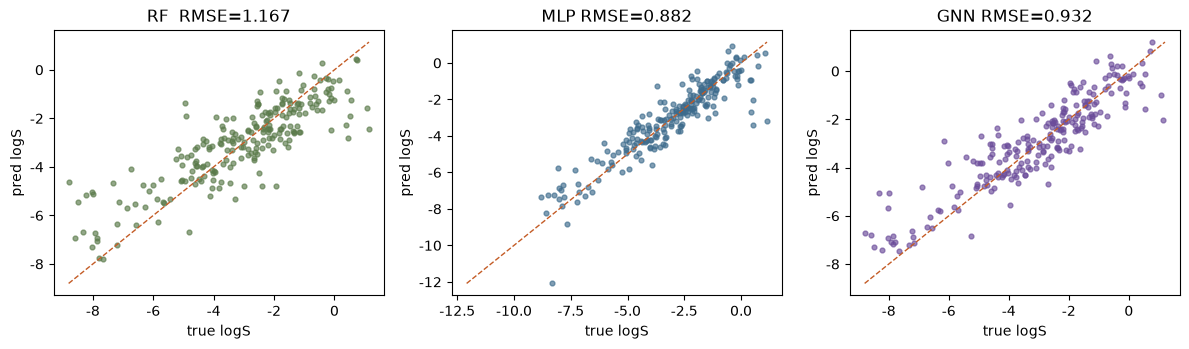

In [11]:
# 汇总三模型指标，方便填简历 / 对比
results = pd.DataFrame([
    {"model": "RF + Morgan FP", "RMSE": rmse_rf, "R2": r2_rf},
    {"model": "MLP + descriptors", "RMSE": rmse_mlp, "R2": r2_mlp},
    {"model": "Tiny MP-GNN + atom graph", "RMSE": gnn_rmse, "R2": gnn_r2},
])
display(results)

# 真值 vs 预测散点：点越靠近对角线 y=x 越好
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
panels = [
    (axes[0], y_test, pred_rf, f"RF  RMSE={rmse_rf:.3f}", "#5a7a4a"),
    (axes[1], y_test, pred_mlp, f"MLP RMSE={rmse_mlp:.3f}", "#3d6b8c"),
    (axes[2], ys_gnn, pred_gnn, f"GNN RMSE={gnn_rmse:.3f}", "#6b4c9a"),
]
for ax, yt, yp, title, color in panels:
    yt = np.asarray(yt)
    yp = np.asarray(yp)
    ax.scatter(yt, yp, s=12, alpha=0.65, c=color)
    lo = min(yt.min(), yp.min())
    hi = max(yt.max(), yp.max())
    ax.plot([lo, hi], [lo, hi], "--", color="#c45c26", linewidth=1)  # 理想线
    ax.set_xlabel("true logS")
    ax.set_ylabel("pred logS")
    ax.set_title(title)
plt.tight_layout()
plt.show()
